[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/grabuffo/brain-modeling-course/blob/main/notebooks/D2_C5_NB09_whole_brain_model.ipynb)

# Day 2 · Chapter 5 · Notebook 09 — A whole-brain model

**Goal.** Put the populations of Chapters 3–4 on a real connectome, simulate the brain at rest, turn the activity into fMRI,
and look at what comes out: **functional connectivity (FC)** organised in networks, and **dynamic FC**, the way these
correlations change over time.

We use the **mouse** brain: its connectome comes from **tracer injections** (Oh et al. 2014), real axonal projections with
directions and strengths, and this model has been used to study mouse resting-state fMRI (Rabuffo et al. 2021, *eNeuro*;
Rabuffo et al. 2025). The same principles apply to the human brain.

The long simulations are precomputed (`dev/cache_nb09.py`, ~30 min); a short one is run live.

In [1]:
# --- Setup (run once) -------------------------------------------------------
# On Google Colab this downloads the course code; on your laptop it does nothing.
import sys, os
if "google.colab" in sys.modules and not os.path.exists("brain-modeling-course"):
    !git clone -q https://github.com/grabuffo/brain-modeling-course.git
    %cd brain-modeling-course/notebooks
    !pip -q install numba ipywidgets
sys.path.insert(0, os.path.abspath(".."))   # so that `import src` works

import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact
from src import plotting
from src.plotting import slider
plotting.setup()
import pandas as pd
from src import connectome, wholebrain, meanfield
sc, labels, centres, cortex = connectome.load_mouse()           # cortex: 50 cortical regions used for FC
sweep = dict(np.load("../data/cache/nb09_sweep.npz"))
G = sweep["G"]
print(f"{sc.shape[0]} regions; precomputed couplings G = {G}")

148 regions; precomputed couplings G = [0.   0.4  0.5  0.55 0.6  0.65 0.7  0.75 0.8  0.9  1.   1.2  1.5 ]


## 1. The ingredients

**1. A node for each brain region**: the Montbrió–Pazó–Roxin population of NB05, in its **bistable** regime: each region
has a low-activity (down) and a high-activity (up) state, like the up and down states of cortex.

**2. The connectome**: region $j$ excites region $i$ through its firing rate, with weight $W_{ij}$.

**3. Global coupling $G$**: one number that scales all connections — the control parameter of the whole brain.

**4. Noise** in every region (all the inputs we do not model).

$$
\tau\dot r_i = \frac{\Delta}{\pi\tau} + 2 r_i v_i,\qquad
\tau\dot v_i = v_i^2 + \eta + J\tau r_i - (\pi\tau r_i)^2 + \underbrace{G\sum_j W_{ij} r_j}_{\text{input from other regions}} + \text{noise}
$$

with $\eta=-4.6$, $J=14.5$, $\Delta=0.7$, $\tau=1$ ms (Rabuffo et al. 2021).

**5. From neurons to fMRI**: the firing rate of each region drives a model of blood flow and oxygenation (the
Balloon–Windkessel model), which produces the BOLD signal, sampled every second as in the scanner.

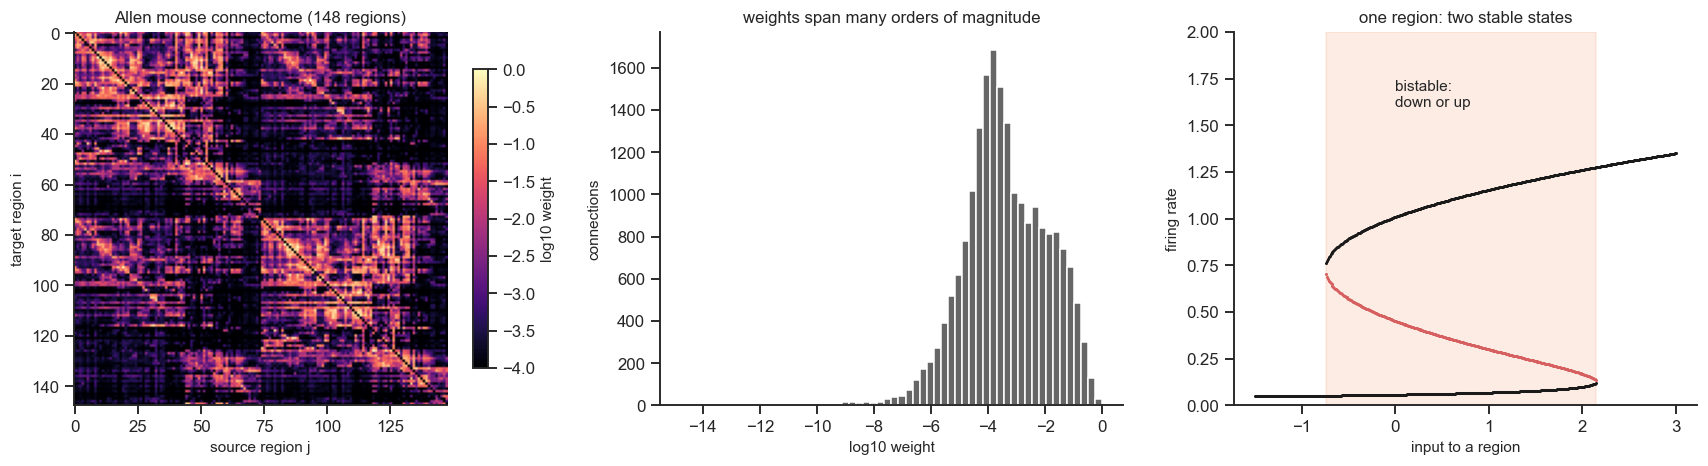

In [2]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.4), gridspec_kw=dict(width_ratios=[1.1, 1, 1]))
im = ax[0].imshow(np.log10(sc + 1e-4), cmap="magma", vmin=-4, vmax=0); plt.colorbar(im, ax=ax[0], shrink=0.8, label="log10 weight")
ax[0].set(title="Allen mouse connectome (148 regions)", xlabel="source region j", ylabel="target region i")
ax[1].hist(np.log10(sc[sc > 0]), bins=60, color="0.4"); ax[1].set(xlabel="log10 weight", ylabel="connections", title="weights span many orders of magnitude")
I_grid = np.linspace(-1.5, 3, 451)
br = meanfield.mpr_branches(I_grid, -4.6, 14.5, 0.7)
for stable, c in [(True, "k"), (False, "C3")]:
    b = np.array([(x[0], x[1]) for x in br if x[3] == stable]); ax[2].plot(b[:, 0], b[:, 1], ".", c=c, ms=2)
ax[2].axvspan(min(x[0] for x in br if not x[3]), max(x[0] for x in br if not x[3]), color="C1", alpha=0.15)
ax[2].text(0.0, 1.6, "bistable:\ndown or up", fontsize=10)
ax[2].set(xlabel="input to a region", ylabel="firing rate", title="one region: two stable states", ylim=(0, 2))
plt.tight_layout()

* Tracer connectomes are **heavy-tailed**: a few strong projections, many weak ones; and directed (not symmetric).
* Without input, each region sits in its down or its up state. Input from other regions shifts it along the horizontal axis:
  enough input from up neighbours can push a region up.

## 2. A short simulation (live)

10 seconds of brain activity at $G=0.6$ (about 30 s to compute on a laptop, 1–2 min on Colab).

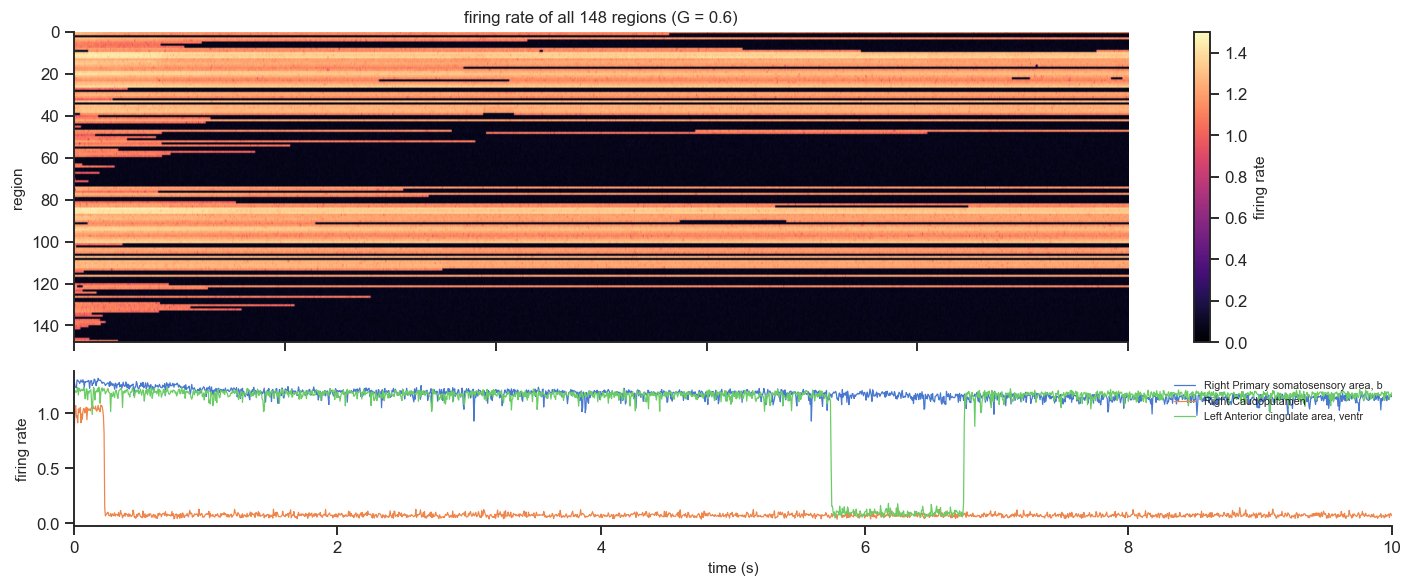

In [3]:
rng = np.random.default_rng(1)
t, r, v = wholebrain.mpr_network(sc, 0.6, T=10_000.0, rec_dt=5.0, eta=-4.6, noise_r=0.01, noise_v=0.02, seed=1,
                                 r0=rng.uniform(0, 2, 148), v0=rng.uniform(-2, 1.5, 148))
fig, ax = plt.subplots(2, 1, figsize=(13, 5.5), sharex=True, gridspec_kw=dict(height_ratios=[2, 1]))
im = ax[0].imshow(r.T, aspect="auto", cmap="magma", vmin=0, vmax=1.5, extent=[0, t[-1] / 1000, 148, 0])
plt.colorbar(im, ax=ax[0], label="firing rate"); ax[0].set(ylabel="region", title="firing rate of all 148 regions (G = 0.6)")
for k in [3, 40, 90]:
    ax[1].plot(t / 1000, r[:, k], lw=0.8, label=labels[k][:35])
ax[1].set(xlabel="time (s)", ylabel="firing rate"); ax[1].legend(fontsize=7, loc="upper right")
plt.tight_layout()

Each region is either in its down state (dark) or in its up state (bright), and sometimes switches. A region that switches up
raises the input to its neighbours, which may switch too: **cascades** of activity travel across the connectome
(Rabuffo et al. 2021).

## 3. How strong should the coupling be?

We now look at 10-minute simulations for many values of $G$ (precomputed), turned into BOLD. Three quantities:
* how often regions are in the up state;
* the **mean FC**: how strongly correlated the regions are on average;
* the **variability of the dynamic FC**: how much the pattern of correlations changes over time (see Section 5).

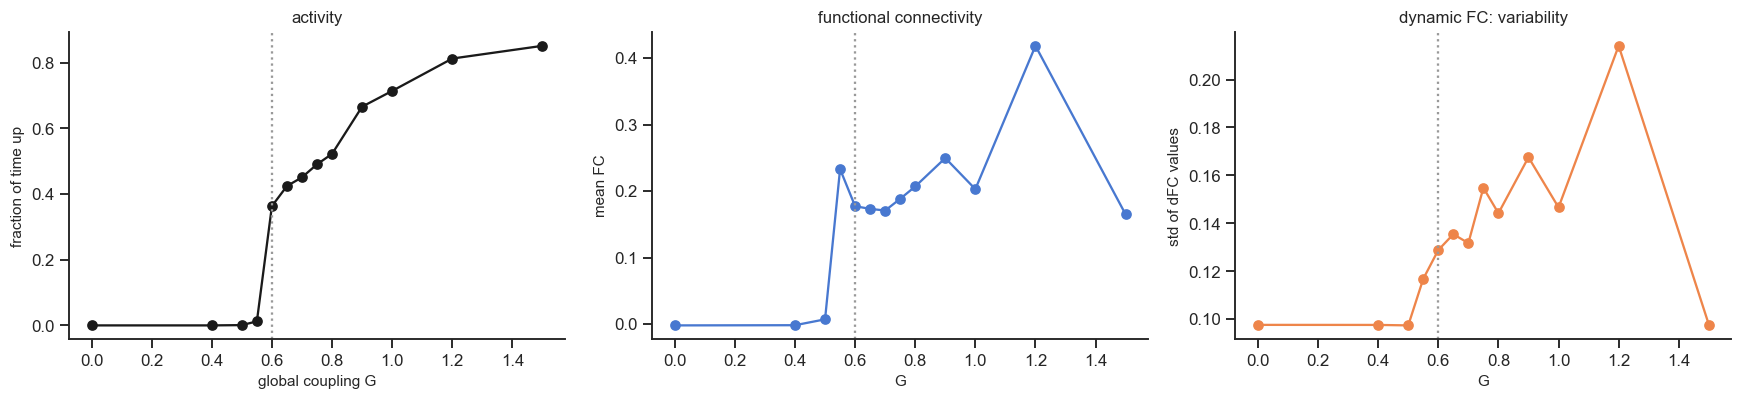

In [4]:
def edges(y):
    z = (y - y.mean(0)) / y.std(0); i, j = np.triu_indices(y.shape[1], 1)
    return z[:, i] * z[:, j]                                      # edge co-activation time series (time, pairs)

def dfc(y):
    return np.corrcoef(edges(y))                                  # time x time similarity of co-activation patterns

u = lambda M: M[np.triu_indices_from(M, 1)]
mean_fc = np.array([u(f).mean() for f in sweep["fc"]])
dfc_var = np.array([d.std() for d in sweep["dfc_values"]])         # spread of the dFC values (precomputed, 160-s windows)

fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
ax[0].plot(G, sweep["frac_up"], "o-", c="k"); ax[0].set(xlabel="global coupling G", ylabel="fraction of time up", title="activity")
ax[1].plot(G, mean_fc, "o-", c="C0"); ax[1].set(xlabel="G", ylabel="mean FC", title="functional connectivity")
ax[2].plot(G, dfc_var, "o-", c="C1"); ax[2].set(xlabel="G", ylabel="std of dFC values", title="dynamic FC: variability")
for a_ in ax: a_.axvline(0.6, c="0.6", ls=":")
plt.tight_layout()

* For weak coupling the regions stay in their down state and fluctuate independently: almost no FC, no dynamics.
* At a critical coupling ($G\approx0.6$) the network starts switching: regions go up and down together in cascades, FC appears,
  and the dynamic FC becomes rich.
* For strong coupling more and more regions lock in the up state.

We use the **working point $G=0.6$, just past the transition** — the network-level bifurcation of the model. This is the
message of Chapter 4 at the scale of the whole brain: close to a bifurcation the system is most sensitive, and its
noise-driven fluctuations look like real brain activity (Rabuffo et al. 2021; Deco & Jirsa 2012).

## 4. Structure and function, organised in networks

Cortical regions belong to resting-state networks. Order the 50 cortical regions by network (and, within each network,
right then left hemisphere), and plot the connectome and the simulated FC with the same order.

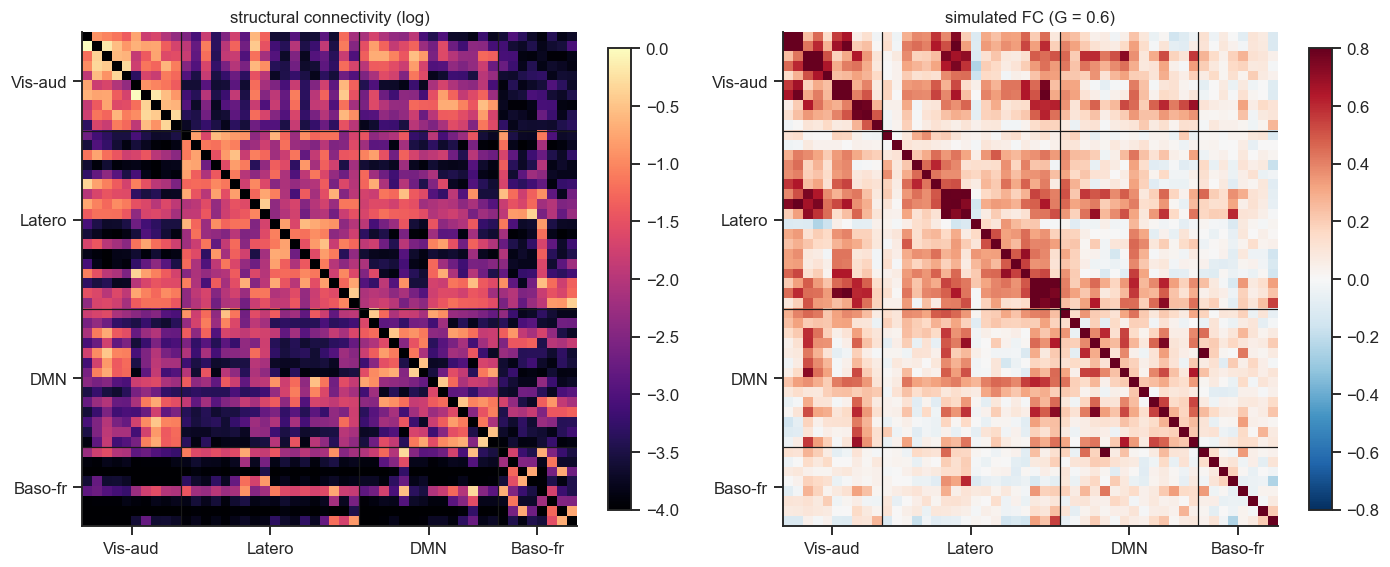

In [5]:
nets = pd.read_csv("../data/mouse/Allen_rois_nets.csv")["Network"].to_numpy()[cortex]
hemi = np.array(["R" if l.startswith("Right") else "L" for l in labels[cortex]])
NETS = ["Visual-auditory", "Laterocortical", "Default mode Network", "Basofrontal"]
order = np.concatenate([np.where((nets == n) & (hemi == h))[0] for n in NETS for h in "RL"])
bounds = np.r_[0, np.cumsum([(nets == n).sum() for n in NETS])]
k06 = int(np.argmin(np.abs(G - 0.6)))
y06 = sweep["bold"][k06][:, cortex]
fc06 = np.corrcoef(y06.T)

fig, ax = plt.subplots(1, 2, figsize=(13, 5.6))
for a_, (M, title, cmap, lo, hi) in zip(ax, [(np.log10(sc[np.ix_(cortex, cortex)] + 1e-4), "structural connectivity (log)", "magma", -4, 0),
                                             (fc06, "simulated FC (G = 0.6)", "RdBu_r", -0.8, 0.8)]):
    im = a_.imshow(M[np.ix_(order, order)], cmap=cmap, vmin=lo, vmax=hi); plt.colorbar(im, ax=a_, shrink=0.8)
    for x in bounds[1:-1]: a_.axhline(x - 0.5, c="k", lw=0.8); a_.axvline(x - 0.5, c="k", lw=0.8)
    ticks = (bounds[:-1] + bounds[1:]) / 2 - 0.5
    a_.set_xticks(ticks, ["Vis-aud", "Latero", "DMN", "Baso-fr"]); a_.set_yticks(ticks, ["Vis-aud", "Latero", "DMN", "Baso-fr"])
    a_.set_title(title)
plt.tight_layout()

The simulated FC is **modular**: regions of the same network are more correlated with each other than with the rest, and
homologous regions of the two hemispheres are correlated (the stripes inside each network block). This organisation comes
from the connectome alone — every region runs the same equations with the same parameters.

## 5. Dynamic functional connectivity

FC is an average over 10 minutes. Does the pattern of correlations stay the same over time? Two views:

* **Co-activation**: multiply the z-scored BOLD of every pair of regions at each time point (an *edge* time series) and sum the
  amplitude over all pairs. Large values are moments when the whole cortex co-activates.
* **Dynamic FC (dFC)**: the similarity between the co-activation patterns at every pair of time points. If the brain always
  had the same pattern, the matrix would be uniform; if patterns changed randomly from moment to moment, it would be bright only
  on the diagonal.

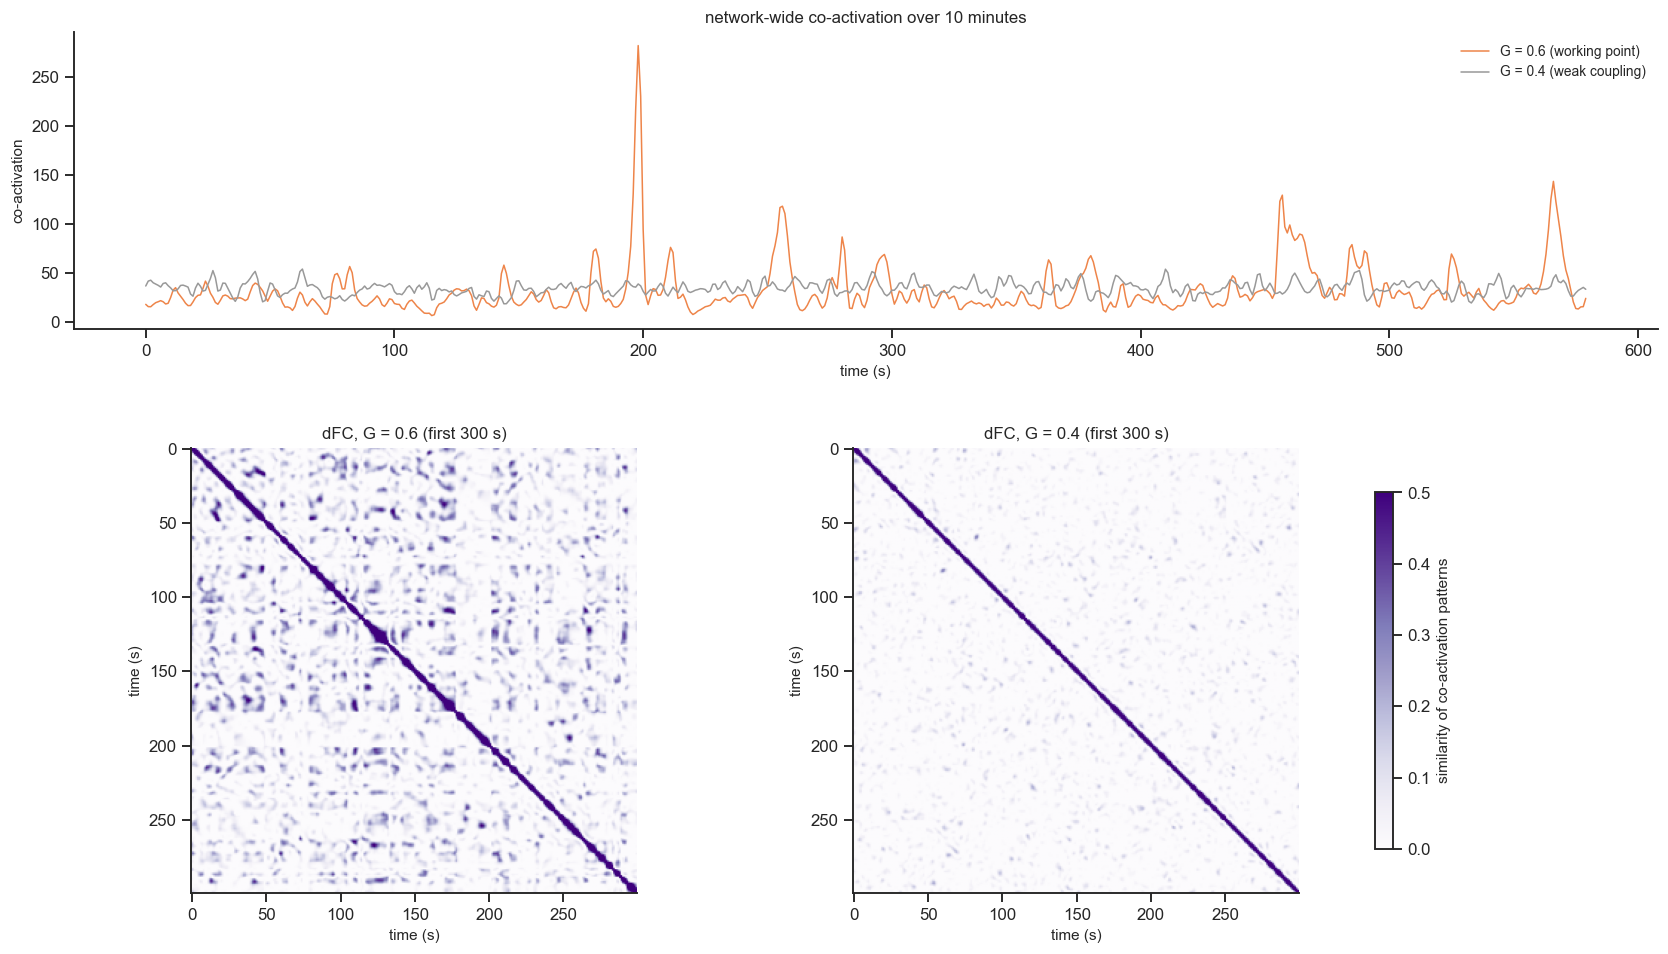

In [6]:
k_low = int(np.argmin(np.abs(G - 0.4)))
y_low = sweep["bold"][k_low][:, cortex]
coact = lambda y: np.sqrt((edges(y) ** 2).sum(1))
fig = plt.figure(figsize=(16, 9))
a0 = fig.add_axes([0.05, 0.62, 0.9, 0.3])
a0.plot(coact(y06), c="C1", lw=1, label="G = 0.6 (working point)")
a0.plot(coact(y_low), c="0.6", lw=1, label="G = 0.4 (weak coupling)")
a0.set(xlabel="time (s)", ylabel="co-activation", title="network-wide co-activation over 10 minutes"); a0.legend(fontsize=9)
for k, (y, title) in enumerate([(y06[:300], "dFC, G = 0.6 (first 300 s)"), (y_low[:300], "dFC, G = 0.4 (first 300 s)")]):
    a_ = fig.add_axes([0.05 + 0.47 * k, 0.05, 0.4, 0.45])
    im = a_.imshow(dfc(y), cmap="Purples", vmin=0, vmax=0.5); a_.set(title=title, xlabel="time (s)", ylabel="time (s)")
plt.colorbar(im, ax=fig.axes[-2:], shrink=0.8, label="similarity of co-activation patterns")

* At the working point the cortex co-activates in **bursts**: short moments in which many regions are correlated at once,
  separated by quiet periods (Rabuffo et al. 2021 called them *neuronal cascades*; similar bursts are seen in human and mouse
  fMRI).
* The dFC matrix is **structured**: bright patches away from the diagonal are moments that share the same pattern of
  co-activation. With weak coupling the matrix is almost empty apart from the diagonal: no network-wide dynamics.

The working point gives what we see in resting-state data: a modular FC, and correlations that are not static but are
organised in time.

### Explore: the coupling

In [7]:
@interact(k=(0, len(G) - 1, 1))
def explore_G(k):
    y = sweep["bold"][k][:, cortex]
    z = (y - y.mean(0)) / y.std(0)
    fig, ax = plt.subplots(1, 3, figsize=(17, 4), gridspec_kw=dict(width_ratios=[2, 1, 1]))
    ax[0].imshow(z[:300, order].T, aspect="auto", cmap="Purples", vmin=0, vmax=2.5)
    ax[0].set(xlabel="time (s)", ylabel="region (by network)", title=f"BOLD, G = {G[k]} (fraction of time up {sweep['frac_up'][k]:.2f})")
    ax[1].imshow(np.corrcoef(y.T)[np.ix_(order, order)], cmap="RdBu_r", vmin=-0.8, vmax=0.8); ax[1].set_title("FC"); ax[1].axis("off")
    ax[2].imshow(dfc(y[:200]), cmap="Purples", vmin=0, vmax=0.5); ax[2].set_title("dFC (200 s)")
    plt.tight_layout(); plt.show()

interactive(children=(IntSlider(value=6, description='k', max=12), Output()), _dom_classes=('widget-interact',…

## 6. Take-home

* A whole-brain model = a population model in every region + the connectome + one global coupling $G$ + noise + a model of the
  BOLD signal.
* Weak coupling: silent and uncorrelated. Strong coupling: regions lock up. In between, just past the transition where regions
  start switching collectively, the model produces a modular FC and a rich dynamic FC, with network-wide co-activation bursts.
* **Next (NB10):** change the excitability of a few regions — a virtual lesion — and see what happens to the whole brain.

### Homework
*To do at home, after the class. In class we use the **Explore** sliders; these exercises take the same
questions further and usually need a few lines of your own code.*
1. **Which regions drive the cascades?** Using `sweep["up_frac_region"]`, plot the fraction of time each region spends up against
   its in-strength (`sc.sum(1)`) at $G=0.6$.
2. **No connectome.** Shuffle the connectome (keep the weights, randomise who connects to whom) and run 2 minutes at $G=0.6$
   (`wholebrain.mpr_network`, ~2 min of compute). Is the FC still modular?
3. **Sliding windows.** Compute FC in 40-s windows sliding by 2 s and correlate the FC of every pair of windows (another common
   definition of dynamic FC). Compare $G=0.4$, $0.6$ and $1.2$.

### References
* Rabuffo G, Fousek J, Bernard C, Jirsa V (2021). Neuronal cascades shape whole-brain functional dynamics at resting state. *eNeuro* 8:ENEURO.0283-21.2021.
* Rabuffo G, Bozzo P, Nguyen B, Depannemaecker D, Pompili M, Gollo L, Fukai T, Sorrentino P, Dalla Porta L (2025). Multiscale brain dynamics at the edge of criticality (preprint; github.com/grabuffo/Multiscale_Brain_Criticality).
* Oh SW et al. (2014). A mesoscale connectome of the mouse brain. *Nature* 508:207. Melozzi F et al. (2017). The Virtual Mouse Brain. *eNeuro* 4:ENEURO.0111-17.2017.
* Friston KJ et al. (2000). Nonlinear responses in fMRI: the Balloon model. *NeuroImage* 12:466.
* Deco G, Jirsa VK (2012). Ongoing cortical activity at rest: criticality, multistability, and ghost attractors. *J Neurosci* 32:3366.
* Zamani Esfahlani F et al. (2020). High-amplitude cofluctuations in cortical activity drive functional connectivity. *PNAS* 117:28393.